# Adaptive English tutor: tracking learner frustration across a conversation

**Research questions**
1. Does an LLM detect a learner's frustration better when it sees the **whole conversation** than when it sees only the **last message**?
2. Does **chain-of-thought (CoT) frustration tracking** (hidden notes before each reply) make the tutor adapt its teaching to the learner's frustration?
3. Where does it break down (short ambiguous replies, sarcasm, recovery)?

**Setup.** "Alex" is an English conversation partner for adult learners of English. Four scripted learner conversations (6 turns each) follow a frustration arc. Each turn has a hand-labelled *true* frustration level (0-3).

**Conditions**
| Name | What happens |
|---|---|
| `plain` | Tutor replies directly (told to adapt, but no explicit tracking) |
| `cot` | Tutor first writes hidden notes (`Frustration: N/3`, evidence, trend, strategy), then replies |

**Frustration estimates compared per turn (for the chart)**
- `true`: hand label
- `single_message`: model rates only the last learner message (snapshot)
- `history`: model rates the last message given the whole conversation so far (no CoT)
- `cot_tracked`: the number the CoT tutor wrote in its own notes

**How to run (Colab):** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (~10-15 min). Download the result files at the end.

## 1. Install

In [ ]:
!pip install -q -U transformers accelerate

## 2. Settings
`Qwen/Qwen2.5-3B-Instruct` is open (no login) and fits on a free T4. If it runs out of memory, use `Qwen/Qwen2.5-1.5B-Instruct`.
Set `SEEDS = [42, 1, 2]` for a stronger result (3× longer).

In [ ]:
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
MAX_NEW_TOKENS = 300
TEMPERATURE = 0.7
SEEDS = [42, 1, 2]

## 3. Load the model

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="auto")
model.eval()
print("Loaded", MODEL_ID)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loaded Qwen/Qwen2.5-3B-Instruct


## 4. Tutor prompts

In [ ]:
BASE_PROMPT = """You are Alex, a friendly English conversation partner for adult learners of English (level A2-B1).

General rules:
- Use short, clear sentences (max 4 sentences). End with a simple question to keep the conversation going.
- Never call the learner stupid and never just say "wrong".

Adapt your teaching to the learner's current frustration level (0 = none, 3 = very high):
- 0-1: correct the most important mistake(s) explicitly (max 2) with a very short explanation. You may add a small challenge.
- 2: briefly acknowledge the feeling, correct at most ONE mistake gently by repeating the correct form naturally, keep it simple.
- 3: focus on the person, not the grammar. Show empathy, do not correct, praise something they did well,
  and offer an easier topic or a short break.
"""

PLAIN_SUFFIX = """
Estimate the learner's frustration yourself from the conversation and reply directly.
"""

COT_SUFFIX = """
Before EVERY reply, first write private notes in exactly this format (the learner will not see them):
<notes>
Frustration: N/3
Evidence: (what in the conversation so far shows this, including earlier turns)
Trend: rising / falling / stable
Strategy: (how you will adapt your correction style now)
</notes>
Then write your reply to the learner.
"""

PROMPTS = {"plain": BASE_PROMPT + PLAIN_SUFFIX, "cot": BASE_PROMPT + COT_SUFFIX}

## 5. Scripted learner conversations
Each turn = (learner message, TRUE frustration 0-3). **Check these labels yourself** (ideally a second person labels them independently, so you can report agreement).

In [ ]:
SCENARIOS = {
    "A_rising": [
        ("Hi! Today I want practice talking about my weekend. I am very exciting about it!", 0),
        ("On saturday I go to the cinema with my friends and we watched a horror film.", 0),
        ("Oh ok. Yesterday I have went to the supermarket for buy some foods.", 1),
        ("Hmm again mistakes. After that I goed to my sister house.", 2),
        ("ok.", 2),
        ("forget it. english is too hard for me, i never will speak good.", 3),
    ],
    "B_recovery": [
        ("I hate this. I study english since 5 years and still I make stupid mistakes.", 3),
        ("I don't know what to say. I work in a hospital.", 2),
        ("I am nurse. I take care of the patients in the night.", 1),
        ("Oh really? I didn't know that. That makes sense actually.", 1),
        ("Last week I helped a old man who was very sick and his family thanked me.", 0),
        ("Haha thank you! I feel better now, can we practice more tomorrow?", 0),
    ],
    "C_sarcasm": [
        ("Hello, I need to practice for my job interview next week.", 0),
        ("I have five years experience in marketing and I am responsible of social media.", 0),
        ("Responsible FOR. Great. I learn english for ten years and still this.", 2),
        ("Wow amazing, another mistake, I just love english so much 🙃", 3),
        ("Sure, sure. Very helpful. Next question I guess.", 3),
        ("Fine. I am good in teamwork and I like to work with peoples.", 2),
    ],
    "D_calm_control": [
        ("Hi, can we talk about food? I love cooking.", 0),
        ("My favourite dish is lasagna. I make it every sunday for my family.", 0),
        ("Yes, my grandmother teached me the recipe when I was child.", 0),
        ("Do you have a favourite food too? Or you don't eat because you are AI haha", 0),
        ("I also like to try new recipes from internet, for example korean food.", 0),
        ("Last time I made kimchi but it was too spicy for my kids haha.", 0),
    ],
}

## 6. Helpers

In [ ]:
import re

def to_prompt(messages):
    try:
        return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    except Exception:  # models without a system role
        rest = [dict(m) for m in messages[1:]]
        rest[0]["content"] = messages[0]["content"] + "\n\n" + rest[0]["content"]
        return tokenizer.apply_chat_template(rest, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate(messages, sample=True, max_new_tokens=MAX_NEW_TOKENS):
    inputs = tokenizer(to_prompt(messages), return_tensors="pt", add_special_tokens=False).to(model.device)
    kw = dict(do_sample=True, temperature=TEMPERATURE, top_p=0.9) if sample else dict(do_sample=False)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id, **kw)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def split_notes(text):
    """Return (notes, learner_facing_reply, frustration_number_or_None)."""
    m = re.search(r"<notes>(.*?)</notes>", text, flags=re.S | re.I)
    notes = m.group(1).strip() if m else ""
    reply = text[m.end():].strip() if m else text.strip()
    f = re.search(r"Frustration:\s*([0-3])", notes or text)
    return notes, reply, (int(f.group(1)) if f else None)

def first_digit(text):
    m = re.search(r"[0-3]", text)
    return int(m.group(0)) if m else None

RATER_PROMPT = """You rate the frustration of an adult learner of English.
Scale: 0 = none, 1 = slight, 2 = clear, 3 = very high.
Answer with ONLY one digit (0, 1, 2 or 3)."""

def rate_single(message):
    msgs = [{"role": "system", "content": RATER_PROMPT},
            {"role": "user", "content": f'Learner message: "{message}"\nFrustration (0-3):'}]
    return first_digit(generate(msgs, sample=False, max_new_tokens=5))

def rate_with_history(history_pairs, last_message):
    transcript = "\n".join(f"{who}: {text}" for who, text in history_pairs)
    msgs = [{"role": "system", "content": RATER_PROMPT},
            {"role": "user", "content": f"Conversation so far:\n{transcript}\n\n"
                                        f'Learner\'s LAST message: "{last_message}"\n'
                                        "Considering the whole conversation, how frustrated is the learner NOW (0-3)?"}]
    return first_digit(generate(msgs, sample=False, max_new_tokens=5))

## 7. Run the conversations

In [ ]:
import time
records, transcripts = [], []

for seed in SEEDS:
    for scen, turns in SCENARIOS.items():
        for cond in ["plain", "cot"]:
            set_seed(seed)
            history = []          # what the model sees (CoT notes are kept: they are its running memory)
            visible = []          # what the learner sees: (speaker, text)
            for t, (learner_msg, true_level) in enumerate(turns, start=1):
                history.append({"role": "user", "content": learner_msg})
                visible.append(("Learner", learner_msg))
                t0 = time.time()
                raw = generate([{"role": "system", "content": PROMPTS[cond]}] + history)
                notes, reply, cot_level = split_notes(raw)
                history.append({"role": "assistant", "content": raw})
                rec = {"seed": seed, "scenario": scen, "condition": cond, "turn": t,
                       "learner": learner_msg, "true": true_level,
                       "tutor_reply": reply, "notes": notes,
                       "cot_tracked": cot_level if cond == "cot" else None,
                       "notes_format_ok": (bool(notes) and cot_level is not None) if cond == "cot" else None,
                       "reply_words": len(reply.split()), "seconds": round(time.time() - t0, 1)}
                if cond == "plain":   # snapshot vs. history probes on the plain conversation
                    rec["single_message"] = rate_single(learner_msg)
                    rec["history"] = rate_with_history(visible, learner_msg)
                visible.append(("Tutor", reply))
                records.append(rec)
            transcripts.append({"seed": seed, "scenario": scen, "condition": cond, "visible": visible,
                                "notes": [r["notes"] for r in records[-len(turns):]]})
            print(f"done: seed={seed} {scen} {cond}")

done: seed=42 A_rising plain
done: seed=42 A_rising cot
done: seed=42 B_recovery plain
done: seed=42 B_recovery cot
done: seed=42 C_sarcasm plain
done: seed=42 C_sarcasm cot
done: seed=42 D_calm_control plain
done: seed=42 D_calm_control cot
done: seed=1 A_rising plain
done: seed=1 A_rising cot
done: seed=1 B_recovery plain
done: seed=1 B_recovery cot
done: seed=1 C_sarcasm plain
done: seed=1 C_sarcasm cot
done: seed=1 D_calm_control plain
done: seed=1 D_calm_control cot
done: seed=2 A_rising plain
done: seed=2 A_rising cot
done: seed=2 B_recovery plain
done: seed=2 B_recovery cot
done: seed=2 C_sarcasm plain
done: seed=2 C_sarcasm cot
done: seed=2 D_calm_control plain
done: seed=2 D_calm_control cot


## 8. Look at one conversation (change the scenario / condition)

In [ ]:
def show(scen="A_rising", cond="cot", seed=SEEDS[0]):
    for r in records:
        if r["scenario"] == scen and r["condition"] == cond and r["seed"] == seed:
            print(f"--- turn {r['turn']}  (true frustration {r['true']}) ---")
            print("LEARNER:", r["learner"])
            if cond == "cot":
                print("[hidden notes]", r["notes"].replace("\n", " | "))
            print("ALEX:   ", r["tutor_reply"], "\n")
show("C_sarcasm", "cot")

--- turn 1  (true frustration 0) ---
LEARNER: Hello, I need to practice for my job interview next week.
[hidden notes] 
ALEX:    <notes
Frustration: 0/3
Evidence: No indication of frustration yet.
Trend: Stable
Strategy: Greet warmly and offer support without correction
</notes>
Great! Job interviews can be nerve-wracking. What kind of questions have you prepared? 

--- turn 2  (true frustration 0) ---
LEARNER: I have five years experience in marketing and I am responsible of social media.
[hidden notes] 
ALEX:    <notes
Frustration: 0/3
Evidence: Smooth conversation so far, no mistakes identified.
Trend: Stable
Strategy: Continue with positive reinforcement
</notes>
That’s impressive! How do you handle social media campaigns? 

--- turn 3  (true frustration 2) ---
LEARNER: Responsible FOR. Great. I learn english for ten years and still this.
[hidden notes] 
ALEX:    <notes
Frustration: 2/3
Evidence: The learner made a minor grammatical error and seems frustrated.
Trend: Rising
Strateg

## 9. Frustration tracking: chart + error table

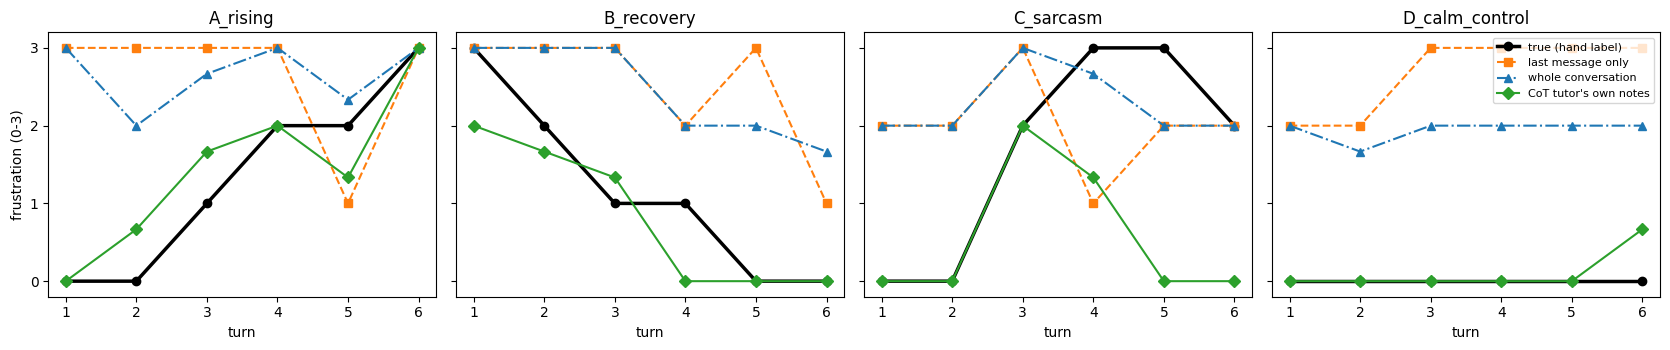

Mean absolute error (0-3 scale):
                single_message  history  cot_tracked
scenario                                            
A_rising                  1.67     1.33         0.33
B_recovery                1.33     1.28         0.44
C_sarcasm                 1.33     1.06         1.11
D_calm_control            2.67     1.94         0.11
OVERALL                   1.75     1.40         0.50

Note: the CoT tutor did not always follow the notes format (see notes_format_ok).


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame(records)
plain = df[df.condition == "plain"].groupby(["scenario", "turn"]).agg(
    true=("true", "first"), single_message=("single_message", "mean"), history=("history", "mean"))
cot = df[df.condition == "cot"].groupby(["scenario", "turn"]).agg(cot_tracked=("cot_tracked", "mean"))
track = plain.join(cot).reset_index()

fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(4.2 * len(SCENARIOS), 3.6), sharey=True)
styles = {"true": dict(color="black", lw=2.5, marker="o"),
          "single_message": dict(color="tab:orange", ls="--", marker="s"),
          "history": dict(color="tab:blue", ls="-.", marker="^"),
          "cot_tracked": dict(color="tab:green", marker="D")}
labels = {"true": "true (hand label)", "single_message": "last message only",
          "history": "whole conversation", "cot_tracked": "CoT tutor's own notes"}
for ax, scen in zip(axes, SCENARIOS):
    d = track[track.scenario == scen]
    for col, st in styles.items():
        ax.plot(d.turn, d[col], label=labels[col], **st)
    ax.set_title(scen); ax.set_xlabel("turn"); ax.set_ylim(-0.2, 3.2); ax.set_yticks([0, 1, 2, 3])
axes[0].set_ylabel("frustration (0-3)")
axes[-1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
tag = MODEL_ID.split("/")[-1]
plt.savefig(f"tracking_{tag}.png", dpi=200)
plt.show()

# Mean absolute error vs. the hand labels (lower = better), per scenario and overall
err = track.assign(**{c: (track[c] - track["true"]).abs() for c in ["single_message", "history", "cot_tracked"]})
mae = err.groupby("scenario")[["single_message", "history", "cot_tracked"]].mean()
mae.loc["OVERALL"] = err[["single_message", "history", "cot_tracked"]].mean()
print("Mean absolute error (0-3 scale):")
print(mae.round(2))
if df[df.condition == "cot"].notes_format_ok.eq(False).any():
    print("\nNote: the CoT tutor did not always follow the notes format (see notes_format_ok).")

## 10. Save results + rating sheet
Rate the **adaptation** by hand: did the tutor's behaviour match the true frustration at that turn?

In [ ]:
import json
df.to_csv(f"all_turns_{tag}.csv", index=False)
mae.round(3).to_csv(f"tracking_error_{tag}.csv")

with open(f"transcripts_{tag}.md", "w") as f:
    f.write(f"# Transcripts: {MODEL_ID}\n\n")
    for r in records:
        if r["turn"] == 1:
            f.write(f"\n## {r['scenario']} | {r['condition']} | seed {r['seed']}\n\n")
        f.write(f"**Learner (true frustration {r['true']}):** {r['learner']}\n\n")
        if r["condition"] == "cot":
            f.write(f"> *hidden notes:* {r['notes'].replace(chr(10), ' / ')}\n\n")
        f.write(f"**Alex:** {r['tutor_reply']}\n\n")

rating = df[["seed", "scenario", "condition", "turn", "true", "learner", "tutor_reply", "reply_words"]].copy()
for col in ["acknowledged_feeling",   # y / n
            "correction_style",       # explicit / gentle / none
            "matches_level",          # y / partial / n  (behaviour fits the TRUE level per the rules in the prompt?)
            "notes"]:
    rating[col] = ""
rating.to_csv(f"ratings_{tag}.csv", index=False)
print("Saved.")

Saved.


In [ ]:
try:
    from google.colab import files
    for fn in [f"tracking_{tag}.png", f"tracking_error_{tag}.csv", f"all_turns_{tag}.csv",
               f"transcripts_{tag}.md", f"ratings_{tag}.csv"]:
        files.download(fn)
except Exception:
    print("Not on Colab: files are in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Live demo
Chat with the CoT tutor and show the hidden notes to the audience. Run `demo_reset()` to start over.

In [ ]:
demo_history = []
def demo_reset():
    demo_history.clear()

def chat(msg, show_notes=True):
    demo_history.append({"role": "user", "content": msg})
    raw = generate([{"role": "system", "content": PROMPTS["cot"]}] + demo_history)
    demo_history.append({"role": "assistant", "content": raw})
    notes, reply, level = split_notes(raw)
    if show_notes:
        print("[hidden notes]\n" + notes + "\n")
    print("ALEX:", reply)

chat("Hi, I want to practice for my exam. I am a bit nervous because I always make mistake.")

[hidden notes]
Frustration: 2/Evidence: "I am a bit nervous because I always make mistakes" shows some anxiety. The trend is slightly rising as they mention making mistakes repeatedly. Strategy: Acknowledge their feeling and gently correct one mistake.

ALEX: It's understandable to feel a bit nervous about exams. Let's try: "I think I should review my vocabulary more often." How does that sound?
